# Student Performance Regression Project

We predict the exam score of students using Linear Regression and Polynomial Regression.

## A. Data Understanding

We import the libraries that we need for data analysis and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

We load the dataset and display its first five rows.

In [2]:
df = pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


We check how many rows and columns the dataset has.

In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (6607, 20)


We display the names of all columns.

In [4]:
print(list(df.columns))

['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


We check the data type of each column and the number of non-null values.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

We display basic statistics for the numerical columns.

In [6]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


We check the number of missing values in each column.

In [7]:
df.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


We calculate the total number of missing values in the dataset.

In [8]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 235


We check if there are any duplicated rows.

In [9]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


We remove duplicated rows only if they exist.

In [10]:
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicates found, so nothing was removed.")

No duplicates found, so nothing was removed.


We print the unique values of each categorical column.

In [11]:
for column in df.select_dtypes(exclude="number").columns:
    print(column, ":", df[column].unique().tolist())

Parental_Involvement : ['Low', 'Medium', 'High']
Access_to_Resources : ['High', 'Medium', 'Low']
Extracurricular_Activities : ['No', 'Yes']
Motivation_Level : ['Low', 'Medium', 'High']
Internet_Access : ['Yes', 'No']
Family_Income : ['Low', 'Medium', 'High']
Teacher_Quality : ['Medium', 'High', 'Low', nan]
School_Type : ['Public', 'Private']
Peer_Influence : ['Positive', 'Negative', 'Neutral']
Learning_Disabilities : ['No', 'Yes']
Parental_Education_Level : ['High School', 'College', 'Postgraduate', nan]
Distance_from_Home : ['Near', 'Moderate', 'Far', nan]
Gender : ['Male', 'Female']


We separate the numerical features from the categorical features.

In [12]:
numerical_features = df.select_dtypes(include="number").columns.drop("Exam_Score").tolist()
categorical_features = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numerical_features)
print()
print("Categorical features:", categorical_features)

Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


We set Exam_Score as the target column that we want to predict.

In [13]:
target_column = "Exam_Score"
print("Target column:", target_column)

Target column: Exam_Score


## B. Exploratory Data Analysis (EDA)

We plot the distribution of Exam_Score to see how the scores are spread.

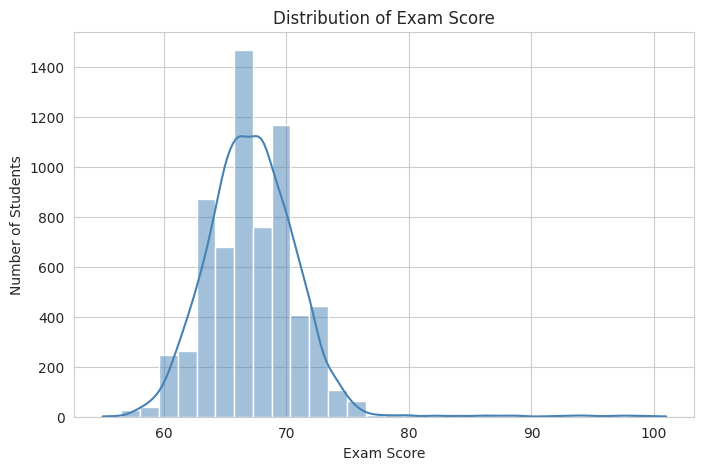

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Exam Score")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.show()

**Observation:** Most students score between about 65 and 69, and a few students have much higher scores.

We draw a boxplot of Exam_Score to look for unusual scores.

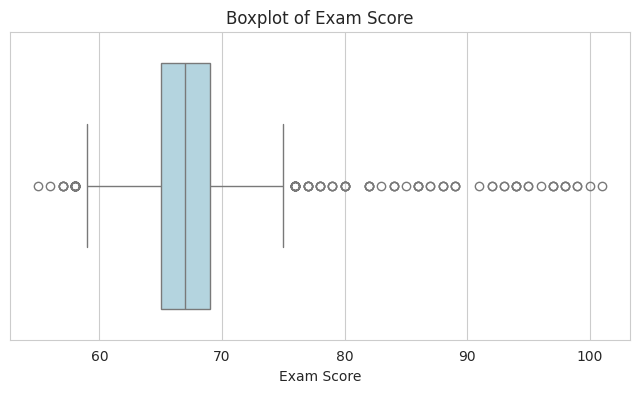

In [15]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Exam_Score"], color="lightblue")
plt.title("Boxplot of Exam Score")
plt.xlabel("Exam Score")
plt.show()

**Observation:** The box is narrow and there are many points outside the whiskers, including one point above 100.

We plot a histogram for each numerical feature.

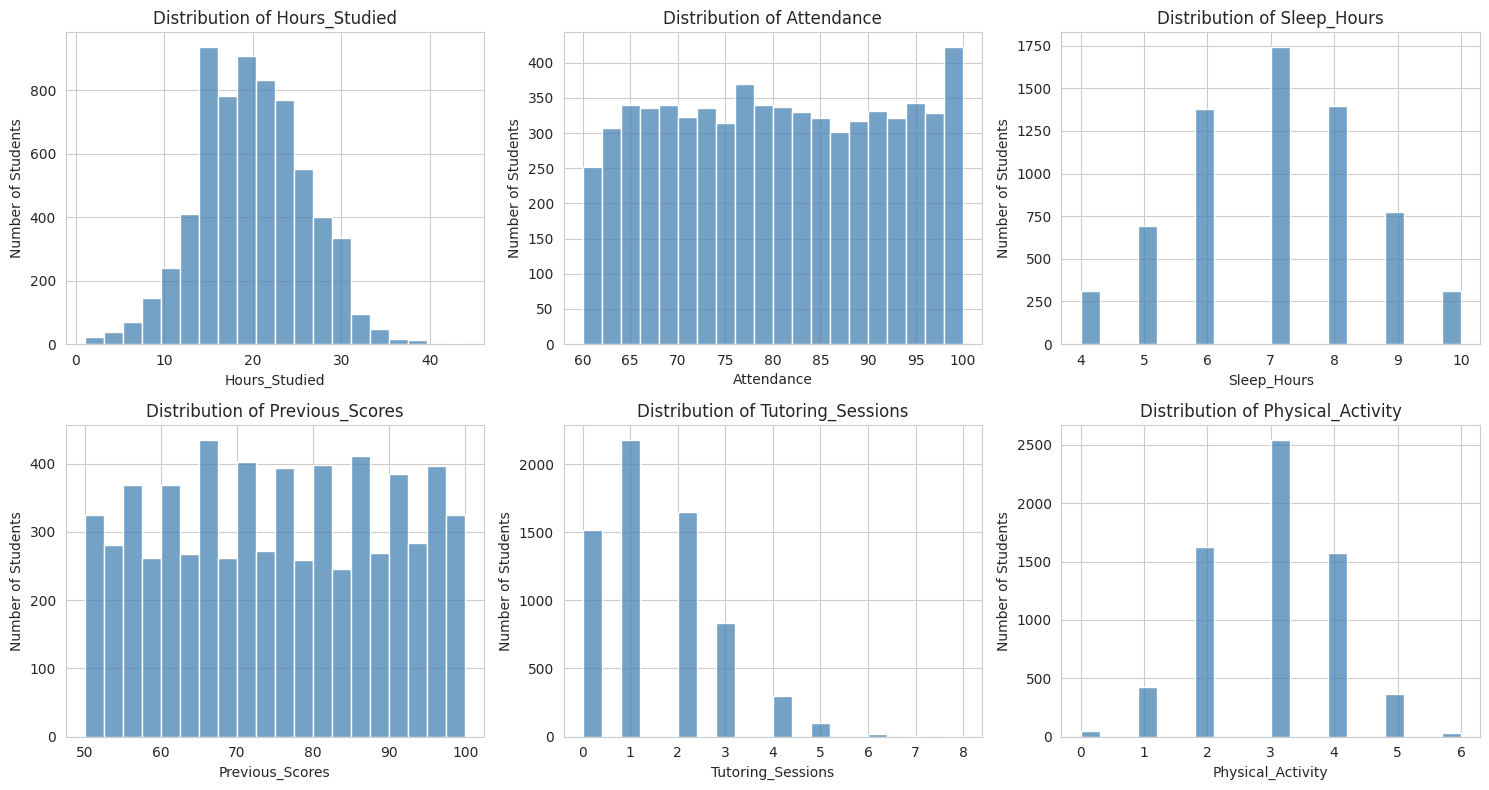

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.histplot(df[column], bins=20, color="steelblue", ax=axes[i])
    axes[i].set_title("Distribution of " + column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

**Observation:** Hours_Studied and Sleep_Hours look bell-shaped, while Attendance and Previous_Scores are spread more evenly.

We choose the important categorical features and put their categories in a clear order.

In [17]:
category_orders = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
}

We draw a count plot for each important categorical feature.

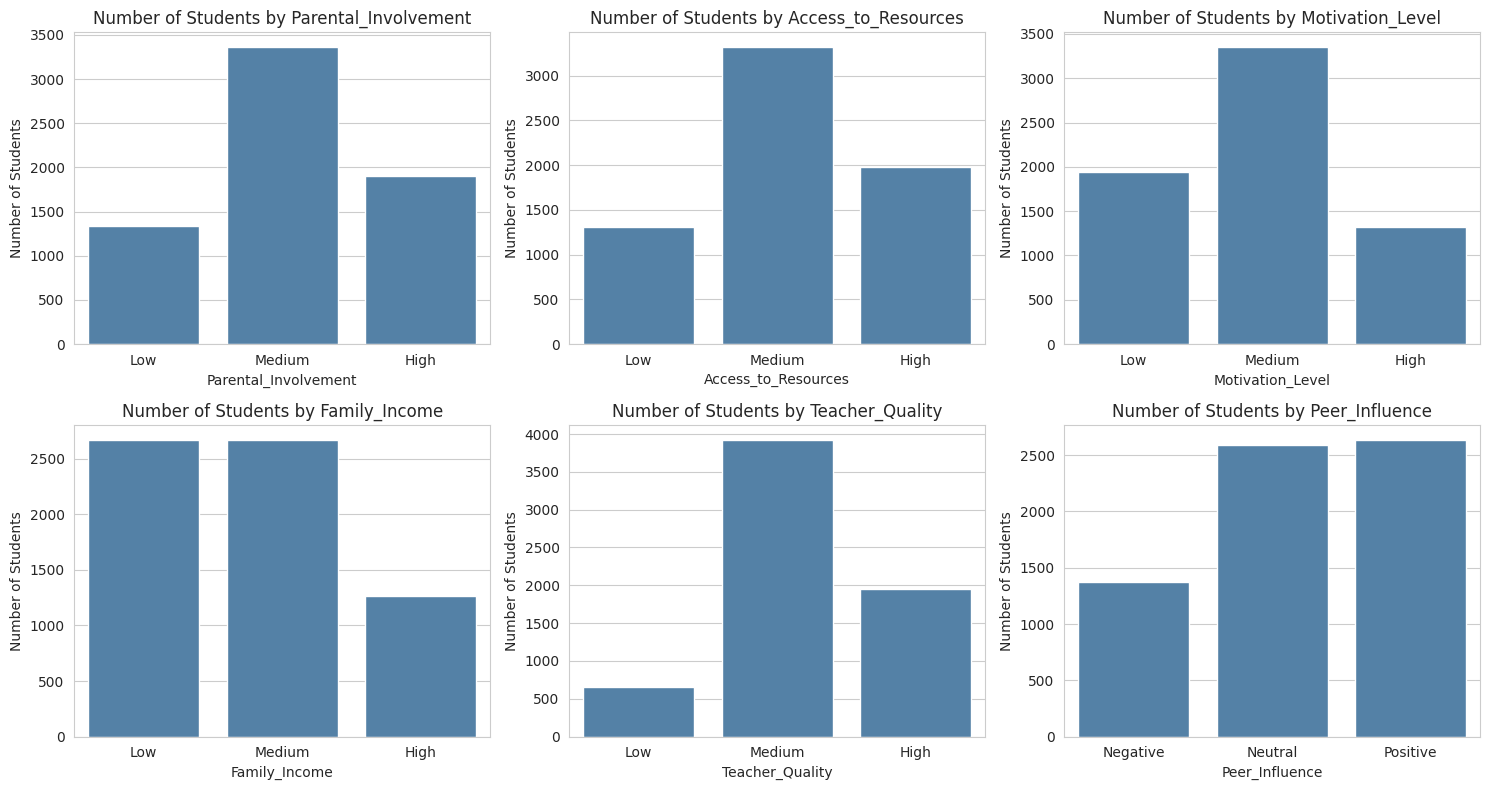

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, column in enumerate(category_orders):
    sns.countplot(data=df, x=column, order=category_orders[column], color="steelblue", ax=axes[i])
    axes[i].set_title("Number of Students by " + column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

**Observation:** Most students have Medium parental involvement, Medium resources and Medium teacher quality.

We draw a correlation heatmap to see which numerical features are related to Exam_Score.

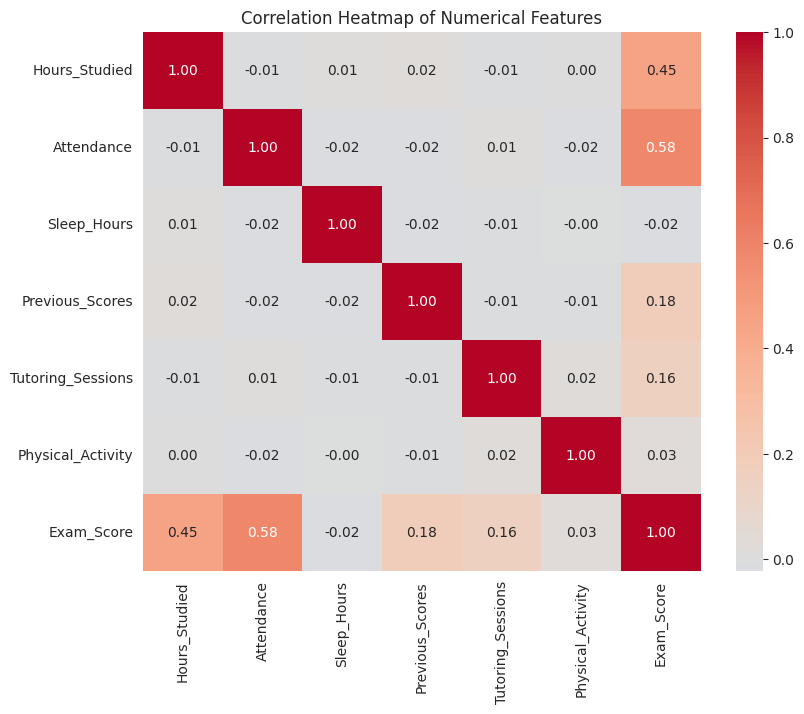

In [19]:
correlation_matrix = df[numerical_features + [target_column]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**Observation:** Attendance (0.58) and Hours_Studied (0.45) have the strongest link with Exam_Score, while Sleep_Hours and Physical_Activity are almost zero.

We draw scatter plots with a red trend line for the four main numerical features against Exam_Score.

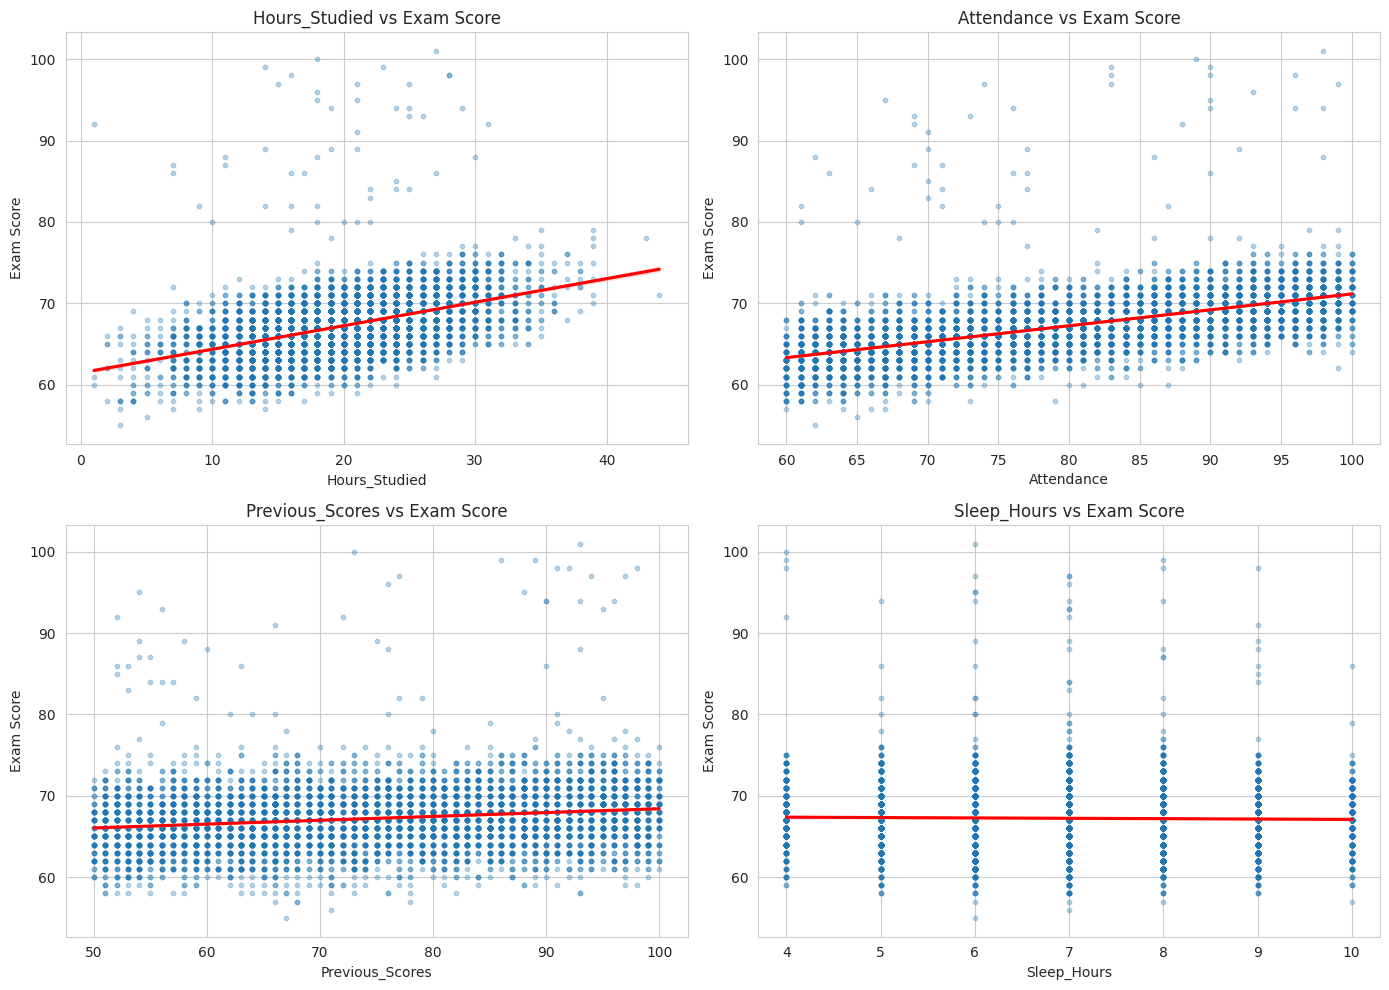

In [20]:
scatter_features = ["Hours_Studied", "Attendance", "Previous_Scores", "Sleep_Hours"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, column in enumerate(scatter_features):
    sns.regplot(data=df, x=column, y="Exam_Score", scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"}, ax=axes[i])
    axes[i].set_title(column + " vs Exam Score")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Exam Score")

plt.tight_layout()
plt.show()

**Observation:** Exam_Score goes up when Attendance and Hours_Studied go up, but it stays flat for Sleep_Hours.

We draw boxplots to compare Exam_Score across the categories of each important categorical feature.

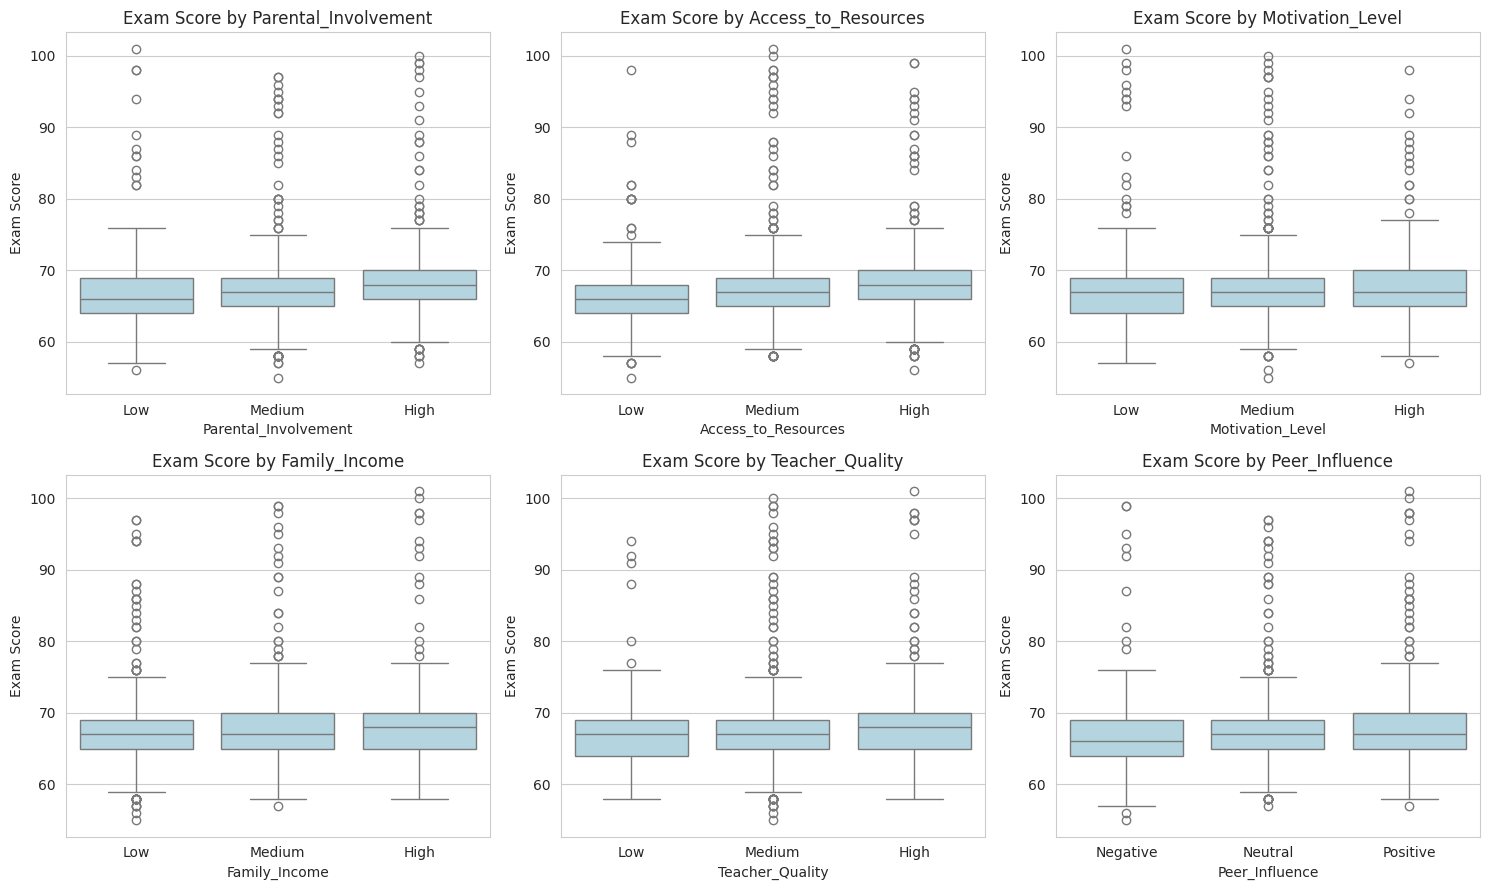

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, column in enumerate(category_orders):
    sns.boxplot(data=df, x=column, y="Exam_Score", order=category_orders[column], color="lightblue", ax=axes[i])
    axes[i].set_title("Exam Score by " + column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Exam Score")

plt.tight_layout()
plt.show()

**Observation:** Higher levels of involvement, resources and motivation give slightly higher scores, but the boxes overlap a lot.

We draw bar charts of the average Exam_Score for three selected categorical features.

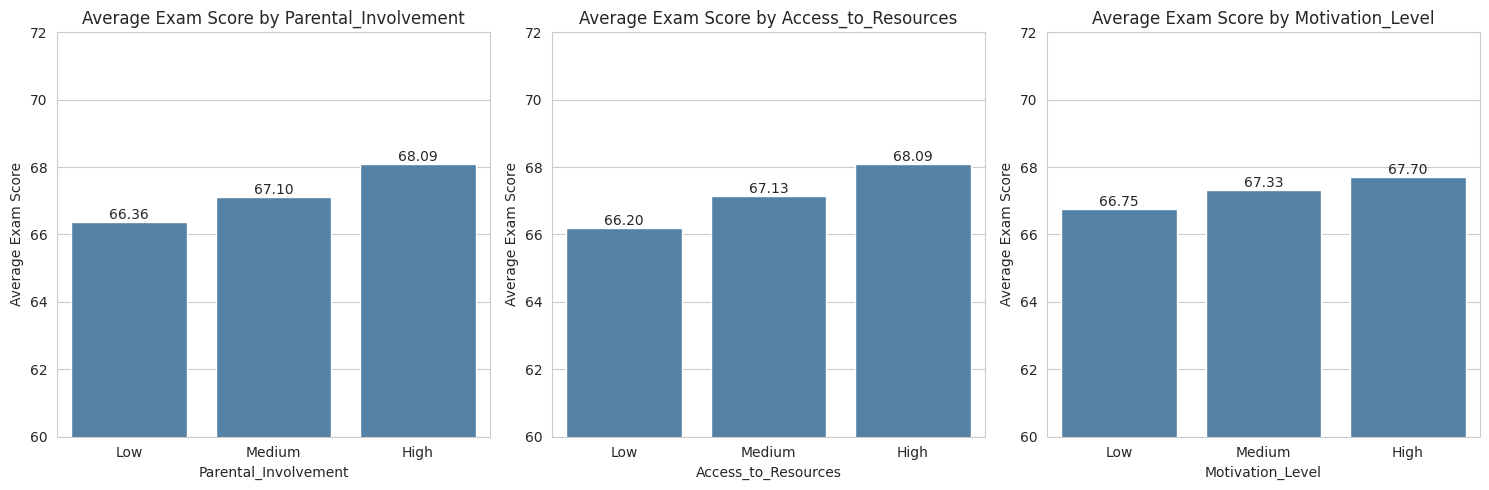

In [22]:
selected_columns = ["Parental_Involvement", "Access_to_Resources", "Motivation_Level"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, column in enumerate(selected_columns):
    sns.barplot(data=df, x=column, y="Exam_Score", order=category_orders[column], color="steelblue", errorbar=None, ax=axes[i])
    axes[i].bar_label(axes[i].containers[0], fmt="%.2f")
    axes[i].set_ylim(60, 72)
    axes[i].set_title("Average Exam Score by " + column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Average Exam Score")

plt.tight_layout()
plt.show()

**Observation:** The average score rises from Low to High in all three charts, but the difference is small (about 1 to 2 points). The y-axis starts at 60 to make this small difference visible.

## C. Data Cleaning and Preprocessing

We list only the columns that have missing values.

In [23]:
missing_counts = df.isnull().sum()
missing_counts[missing_counts > 0]

,0
Teacher_Quality,78
Parental_Education_Level,90
Distance_from_Home,67


**Observation:** Only three categorical columns have missing values: Teacher_Quality, Parental_Education_Level and Distance_from_Home. No numerical column has missing values.

We check for invalid values such as scores above 100 or negative numbers.

In [24]:
print("Exam_Score above 100:", (df["Exam_Score"] > 100).sum())
print("Attendance above 100:", (df["Attendance"] > 100).sum())
print("Previous_Scores above 100:", (df["Previous_Scores"] > 100).sum())
print("Negative values:", (df[numerical_features + [target_column]] < 0).sum().sum())

Exam_Score above 100: 1
Attendance above 100: 0
Previous_Scores above 100: 0
Negative values: 0


We look at the row that has an Exam_Score above 100.

In [25]:
df[df["Exam_Score"] > 100]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


**Observation:** An exam score cannot be above 100, and this student looks strong (Previous_Scores 93, Attendance 98), so 101 is most likely a typing mistake. It is only one row out of 6607, so we remove it.

We remove the row with the invalid Exam_Score.

In [26]:
df = df[df["Exam_Score"] <= 100].reset_index(drop=True)
print("New shape:", df.shape)

New shape: (6606, 20)


We draw boxplots of the numerical features to check for outliers.

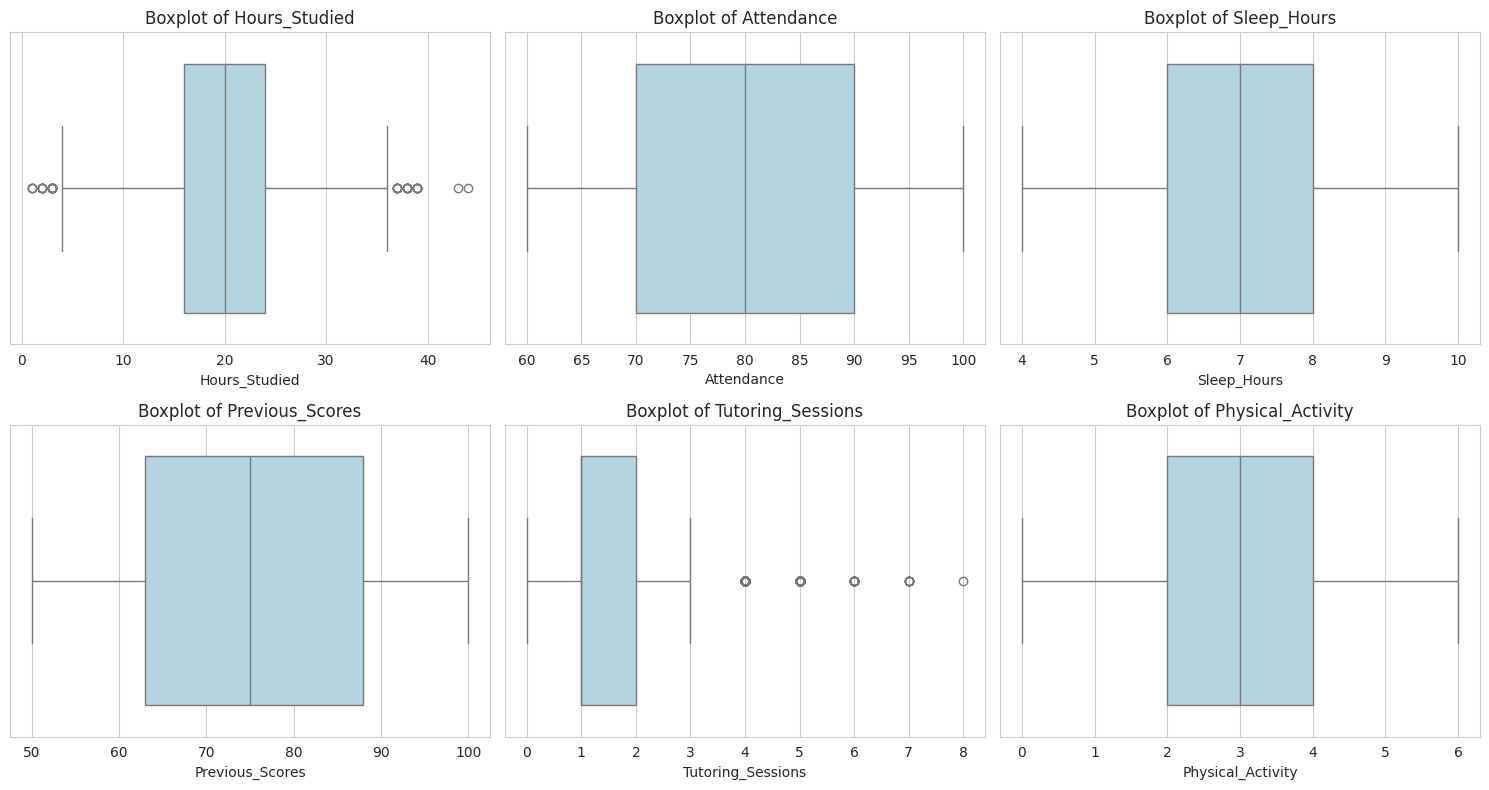

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.boxplot(x=df[column], color="lightblue", ax=axes[i])
    axes[i].set_title("Boxplot of " + column)
    axes[i].set_xlabel(column)

plt.tight_layout()
plt.show()

**Observation:** Hours_Studied and Tutoring_Sessions have some high values, but they are realistic (for example 44 study hours or 8 sessions), so we keep all of them.

We separate the features X from the target y.

In [28]:
X = df.drop(columns=[target_column])
y = df[target_column]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6606, 19)
y shape: (6606,)


We split the data into 80% training and 20% testing before any preprocessing, so the test data stays unseen.

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = X_train.copy()
X_test = X_test.copy()

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5284
Testing rows: 1322


We fill the missing categorical values with the mode of the training data.

In [30]:
for column in categorical_features:
    most_common_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(most_common_value)
    X_test[column] = X_test[column].fillna(most_common_value)

We fill the missing numerical values with the median of the training data.

In [31]:
for column in numerical_features:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

We confirm that no missing values are left in the training and testing data.

In [32]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


We convert the categorical columns into numbers using One-Hot Encoding.

In [33]:
X_train_encoded = pd.get_dummies(X_train, columns=categorical_features, drop_first=True, dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_features, drop_first=True, dtype=int)

X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("Training shape after encoding:", X_train_encoded.shape)
print("Testing shape after encoding:", X_test_encoded.shape)

Training shape after encoding: (5284, 27)
Testing shape after encoding: (1322, 27)


We check that the training and testing data have exactly the same columns.

In [34]:
print("Same columns in the same order:", list(X_train_encoded.columns) == list(X_test_encoded.columns))

Same columns in the same order: True


We scale the numerical columns using the mean and standard deviation of the training data only.

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(X_train_encoded[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test_encoded[numerical_features])

We check that the scaled training columns have a mean near 0 and a standard deviation near 1.

In [36]:
X_train_scaled[numerical_features].describe().round(2)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
count,5284.00,5284.00,5284.00,5284.00,5284.00,5284.00
mean,-0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.19,-1.73,-2.06,-1.74,-1.21,-2.89
25%,-0.67,-0.87,-0.70,-0.84,-0.40,-0.95
50%,-0.00,0.00,-0.02,-0.00,-0.40,0.03
75%,0.67,0.87,0.67,0.83,0.41,1.00
max,4.02,1.73,2.03,1.74,5.28,2.94


We look at the first five rows of the final training data.

In [37]:
X_train_scaled.head()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,Access_to_Resources_Medium,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
5936,-1.509761,-0.433104,1.345705,0.136860,-0.398416,-0.945182,0,0,0,0,...,0,0,1,0,1,0,0,1,0,1
4416,-2.012507,-0.606517,0.665320,0.206483,-1.209679,0.025913,0,1,0,0,...,0,0,0,0,0,1,0,0,1,1
2948,-1.677343,-0.346398,-2.056220,-0.489743,-0.398416,2.939199,0,1,1,0,...,0,0,1,0,0,0,0,0,1,1
3085,-0.001522,0.347251,-0.015065,-0.072007,-0.398416,0.025913,1,0,1,0,...,1,1,1,0,0,0,1,0,1,0
5819,-0.001522,-1.560285,-2.056220,1.598934,-0.398416,0.997008,0,1,0,1,...,0,1,0,0,0,1,0,0,1,1


## D. Linear Regression

We import the LinearRegression class from scikit-learn.

In [38]:
from sklearn.linear_model import LinearRegression

We create the Linear Regression model.

In [39]:
linear_model = LinearRegression()

We train the model using the training data.

In [40]:
linear_model.fit(X_train_scaled, y_train)

LinearRegression()

We predict the exam scores of the testing data.

In [41]:
y_pred_linear = linear_model.predict(X_test_scaled)

We compare ten actual scores with the predicted scores.

In [42]:
linear_comparison = pd.DataFrame({
    "Actual Score": y_test.values[:10],
    "Predicted Score": y_pred_linear[:10].round(2)
})
linear_comparison

,Actual Score,Predicted Score
0,66,66.01
1,66,65.45
2,67,67.58
3,67,67.65
4,68,68.01
5,63,63.25
6,74,74.01
7,65,65.07
8,69,68.97
9,76,75.71


We import the functions that calculate the evaluation metrics.

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

We calculate MAE, MSE, RMSE and R² for the Linear Regression model.

In [44]:
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred_linear)

print("MAE  :", round(linear_mae, 4))
print("MSE  :", round(linear_mse, 4))
print("RMSE :", round(linear_rmse, 4))
print("R2   :", round(linear_r2, 4))

MAE  : 0.416
MSE  : 2.3142
RMSE : 1.5213
R2   : 0.825


**What the metrics mean:**
- **MAE:** the average size of the error in score points.
- **MSE:** the average of the squared errors, so big mistakes count more.
- **RMSE:** the square root of MSE, so it is in score points again.
- **R²:** the part of the score changes that the model explains (1 is perfect, 0 is no better than the average).

**Observation:** On average the model is wrong by about 0.42 points (MAE), and it explains about 82.5% of the changes in exam score (R²). RMSE (1.52) is bigger than MAE because a few students have very large errors.

## E. Polynomial Regression

Polynomial Regression adds squared and interaction terms so the model can learn curved relationships, and we start by importing PolynomialFeatures.

In [45]:
from sklearn.preprocessing import PolynomialFeatures

We create PolynomialFeatures with degree 2.

In [46]:
polynomial_features = PolynomialFeatures(degree=2, include_bias=False)

We learn the polynomial terms from the training data and apply them to both training and testing data.

In [47]:
X_train_poly = polynomial_features.fit_transform(X_train_scaled)
X_test_poly = polynomial_features.transform(X_test_scaled)

print("Features before:", X_train_scaled.shape[1])
print("Features after:", X_train_poly.shape[1])

Features before: 27
Features after: 405


We create a new Linear Regression model and train it on the polynomial features.

In [48]:
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

LinearRegression()

We predict the exam scores of the testing data with the polynomial model.

In [49]:
y_pred_poly = poly_model.predict(X_test_poly)

We compare ten actual scores with the predicted scores of the polynomial model.

In [50]:
poly_comparison = pd.DataFrame({
    "Actual Score": y_test.values[:10],
    "Predicted Score": y_pred_poly[:10].round(2)
})
poly_comparison

,Actual Score,Predicted Score
0,66,66.38
1,66,65.45
2,67,67.81
3,67,66.85
4,68,67.16
5,63,62.54
6,74,75.16
7,65,64.40
8,69,68.70
9,76,75.30


We calculate MAE, MSE, RMSE and R² for the Polynomial Regression model.

In [51]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_mse = mean_squared_error(y_test, y_pred_poly)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_pred_poly)

print("MAE  :", round(poly_mae, 4))
print("MSE  :", round(poly_mse, 4))
print("RMSE :", round(poly_rmse, 4))
print("R2   :", round(poly_r2, 4))

MAE  : 0.6317
MSE  : 2.6506
RMSE : 1.6281
R2   : 0.7996


## F. Model Comparison

We put the results of both models in one table using the same test data.

In [52]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [linear_mae, poly_mae],
    "MSE": [linear_mse, poly_mse],
    "RMSE": [linear_rmse, poly_rmse],
    "R2 Score": [linear_r2, poly_r2]
})
comparison.round(4)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.4160,2.3142,1.5213,0.8250
1,Polynomial Regression,0.6317,2.6506,1.6281,0.7996


We compare the R² on training data and testing data to check for overfitting.

In [53]:
train_r2_linear = r2_score(y_train, linear_model.predict(X_train_scaled))
train_r2_poly = r2_score(y_train, poly_model.predict(X_train_poly))

overfitting_check = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "Train R2": [train_r2_linear, train_r2_poly],
    "Test R2": [linear_r2, poly_r2]
})
overfitting_check.round(4)

,Model,Train R2,Test R2
0,Linear Regression,0.7110,0.8250
1,Polynomial Regression,0.7303,0.7996


We draw a bar chart to compare the MAE of both models (lower is better).

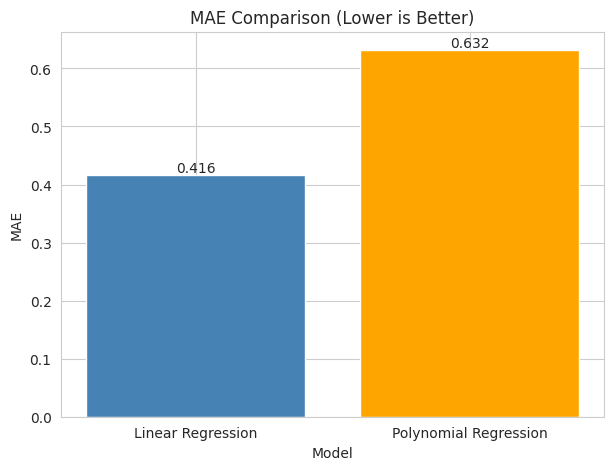

In [54]:
plt.figure(figsize=(7, 5))
bars = plt.bar(comparison["Model"], comparison["MAE"], color=["steelblue", "orange"])
plt.bar_label(bars, fmt="%.3f")
plt.title("MAE Comparison (Lower is Better)")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.show()

We draw a bar chart to compare the RMSE of both models (lower is better).

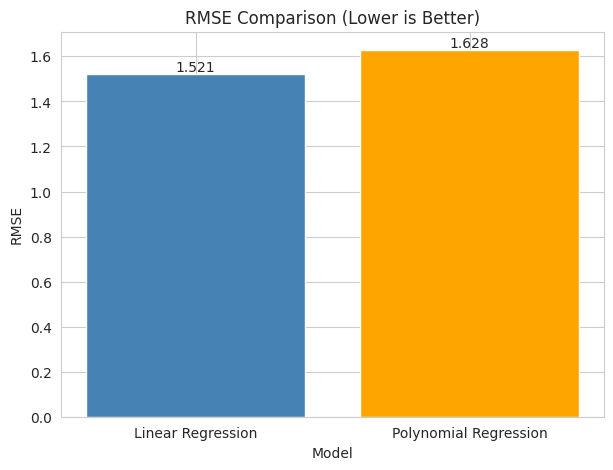

In [55]:
plt.figure(figsize=(7, 5))
bars = plt.bar(comparison["Model"], comparison["RMSE"], color=["steelblue", "orange"])
plt.bar_label(bars, fmt="%.3f")
plt.title("RMSE Comparison (Lower is Better)")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.show()

We draw a bar chart to compare the R² score of both models (higher is better).

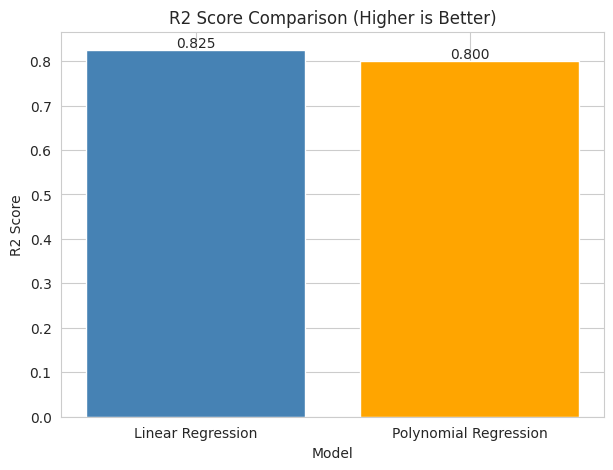

In [56]:
plt.figure(figsize=(7, 5))
bars = plt.bar(comparison["Model"], comparison["R2 Score"], color=["steelblue", "orange"])
plt.bar_label(bars, fmt="%.3f")
plt.title("R2 Score Comparison (Higher is Better)")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.show()

We plot actual scores against predicted scores for Linear Regression.

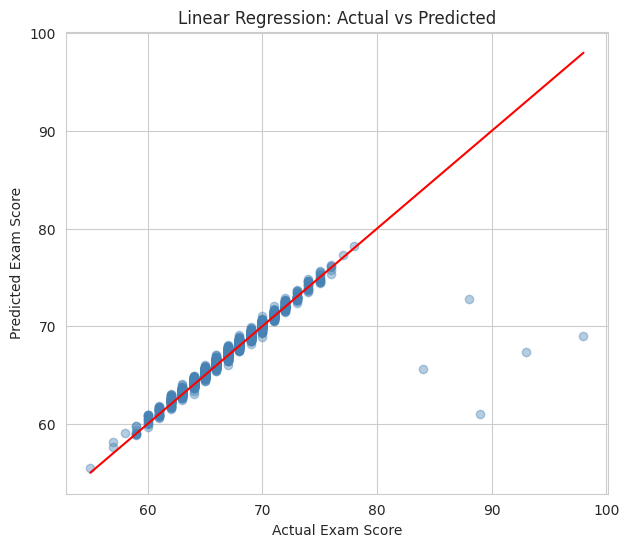

In [57]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_linear, alpha=0.4, color="steelblue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.show()

We plot actual scores against predicted scores for Polynomial Regression.

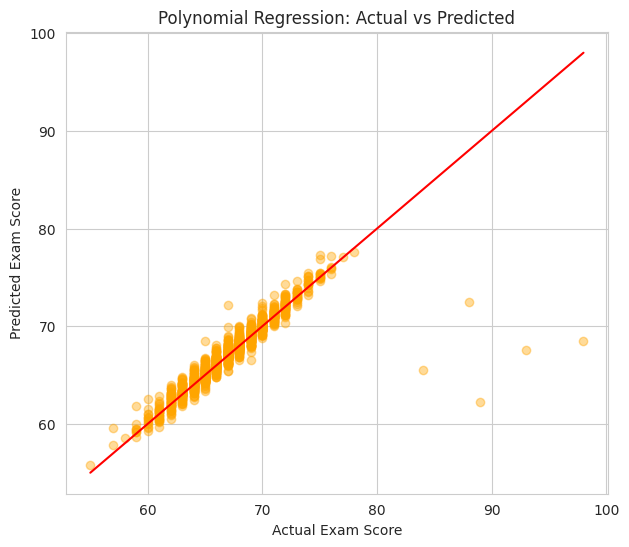

In [58]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_poly, alpha=0.4, color="orange")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.show()

**Observation:** The closer the points are to the red line, the better the predictions.

We plot the residuals (actual minus predicted) of both models.

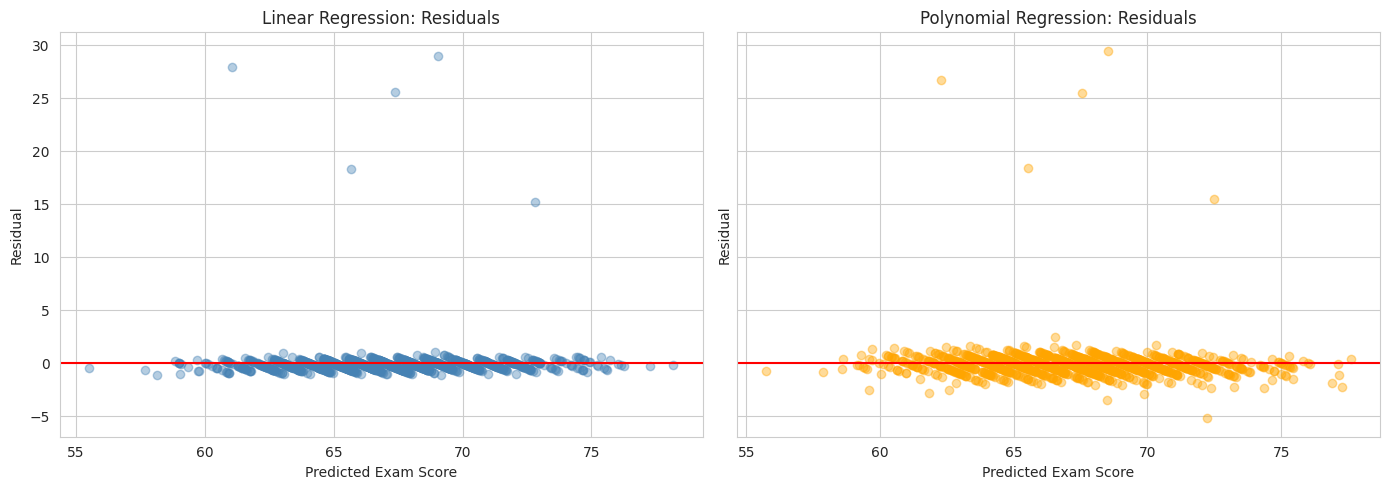

In [59]:
residuals_linear = y_test - y_pred_linear
residuals_poly = y_test - y_pred_poly

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].scatter(y_pred_linear, residuals_linear, alpha=0.4, color="steelblue")
axes[0].axhline(0, color="red")
axes[0].set_title("Linear Regression: Residuals")
axes[0].set_xlabel("Predicted Exam Score")
axes[0].set_ylabel("Residual")

axes[1].scatter(y_pred_poly, residuals_poly, alpha=0.4, color="orange")
axes[1].axhline(0, color="red")
axes[1].set_title("Polynomial Regression: Residuals")
axes[1].set_xlabel("Predicted Exam Score")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

**Observation:** For both models most residuals are close to 0, but a few students have very large residuals (up to about 30 points), which the features cannot explain.

We let the metrics decide which model is better.

In [60]:
best_by_rmse = comparison.loc[comparison["RMSE"].idxmin(), "Model"]
best_by_r2 = comparison.loc[comparison["R2 Score"].idxmax(), "Model"]

print("Best model by RMSE:", best_by_rmse)
print("Best model by R2:", best_by_r2)

Best model by RMSE: Linear Regression
Best model by R2: Linear Regression


**Result:** Linear Regression performed better, with lower MAE (0.416 vs 0.632), lower MSE (2.314 vs 2.651), lower RMSE (1.521 vs 1.628) and higher R² (0.825 vs 0.800).

**Why:** The relationship between the features and Exam_Score is mostly a straight line, so the 405 polynomial features added complexity without adding accuracy. Polynomial Regression has a slightly higher Train R² (0.730 vs 0.711) but a lower Test R² (0.800 vs 0.825), which is a sign of overfitting.

**Note:** Test R² is higher than Train R² for both models because the training data happens to contain more students with very large errors (44 students with an error above 5 points, compared with 5 in the test data). This comes from the random split and is not a mistake in the code.

## G. Final Conclusion

We print the final results one more time so the conclusion is based on real numbers.

In [61]:
comparison.round(4)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.4160,2.3142,1.5213,0.8250
1,Polynomial Regression,0.6317,2.6506,1.6281,0.7996
